# 09 — Does the Link Differ for Male and Female Respondents?

## Purpose

> **Exploratory analysis.** Our main (confirmatory) analysis is the association between parental education and traditional gender-role attitudes in `03_correlations.ipynb`. This notebook is **exploratory**: sex differences were not part of our original hypotheses, and we run several interaction tests. All results are cross-sectional **associations**, based on complete cases and **unweighted** data.

In `06_multivariate_models.ipynb`, sex was one of the strongest predictors of gender-role attitudes: women were clearly less traditional than men. In this notebook we ask a different question: is the **association between parental education and gender-role attitudes** the same for men and women?

There are two reasons this might differ:

1. **Same-sex role models:** socialisation theory suggests that children may model themselves more on the parent of the same sex. If so, **mother's education** might matter more for **daughters**, and **father's education** more for **sons**.
2. **Who benefits from egalitarian values:** less traditional gender-role attitudes directly benefit women (e.g. access to education and leadership). Daughters of educated parents may therefore take up these values more readily than sons, so parental education in general might matter more for **women**.

We test this with interaction terms between parental education and sex, in the same way as the `ba_binary:sex_woman` interaction in Week 6 and the moderation models in `05_moderation.ipynb`.

### Hypotheses

**H0d:** The association between parental education and traditional gender-role attitudes is the same for men and women (interaction = 0).

**H1d:** The association between parental education and traditional gender-role attitudes differs between men and women (interaction ≠ 0).

We test this separately for mother's and father's education. All tests are two-tailed.

## 1. Setup and Data Loading

We use the same packages as in notebooks 03 and 05.

In [1]:
from pathlib import Path  # used to build file paths that work on any computer

import pandas as pd  # data management (DataFrames)
import numpy as np  # numerical tools
from plotnine import *  # ggplot-style figures, as used in class
import warnings  # lets us silence routine warnings
warnings.filterwarnings('ignore')  # hide warnings so the output is easier to read
import statsmodels.formula.api as smf  # OLS regression with formulas (Weeks 5-6)
from stargazer.stargazer import Stargazer  # regression tables
from scipy import stats  # Spearman correlation and t-distribution

In [2]:
# Identify the root folder of the GitHub repository.
PROJECT_ROOT = Path.cwd()  # start from the folder the notebook is running in
if PROJECT_ROOT.name == "code":  # if we are inside the /code folder...
    PROJECT_ROOT = PROJECT_ROOT.parent  # ...move up one level to the repository root

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "WVS_Singapore_full_cleaned.csv"  # cleaned dataset (notebooks 04, 07 and 08)
OUTPUT_FIGURES = PROJECT_ROOT / "output" / "figures"  # folder for saved figures
OUTPUT_TABLES = PROJECT_ROOT / "output" / "tables"  # folder for saved tables

df = pd.read_csv(DATA_PATH)  # load the cleaned dataset
outcome = "traditional_gender_attitudes"  # outcome: higher = more traditional (1-4)
df["sex"] = df["female"].map({0.0: "Male", 1.0: "Female"})  # readable sex labels for tables and plots
print(f"Number of respondents: {df.shape[0]}")  # number of rows

Number of respondents: 2012


## 2. Descriptive Statistics by Sex

We first compare the gender-role scores of men and women, and check whether men and women in our sample report similar levels of parental education. If one group had much more educated parents, this could affect the comparison.

In [3]:
sex_desc = df.groupby("sex").agg(  # one row per sex
    N=(outcome, "count"),  # number of valid gender-role scores
    Mean_attitudes=(outcome, "mean"),  # mean gender-role score
    SD_attitudes=(outcome, "std"),  # standard deviation
    Mean_mother_edu=("Q277R", "mean"),  # mean mother's education level (1-3)
    Mean_father_edu=("Q278R", "mean"),  # mean father's education level (1-3)
    Mean_age=("Q262", "mean"),  # mean age
).reindex(["Male", "Female"])  # fixed order of rows

sex_desc.to_csv(OUTPUT_TABLES / "sex_differences_descriptives.csv")  # save the table
sex_desc.round(3)  # display the table

,N,Mean_attitudes,SD_attitudes,Mean_mother_edu,Mean_father_edu,Mean_age
sex,,,,,,
Male,905,2.195,0.555,1.413,1.559,47.342
Female,1065,2.051,0.549,1.395,1.516,48.158


### Interpretation

Women in our sample hold **less traditional** gender-role attitudes than men (**M = 2.051** vs. **2.195**, a difference of about 0.14 points on the 1–4 scale). This matches the strong negative coefficient for `female` in `06_multivariate_models.ipynb`.

Men and women report very similar parental education: the mean mother's education level is 1.413 for men and 1.395 for women, and the mean father's education level is 1.559 and 1.516. Their average age is also similar (47.3 vs. 48.2 years). So any difference in the *link* between parental education and attitudes is unlikely to be caused by men and women simply having parents with different levels of education.

## 3. Spearman Correlations Separately for Men and Women

As a first, **descriptive** step, we repeat the Spearman correlations from `03_correlations.ipynb` separately for men and women. This shows the strength of the association in each group, using the same method as before. These correlations are secondary: the formal test is the interaction model in Section 4.

In [4]:
parents = {"Q277R": "Mother's education", "Q278R": "Father's education"}  # the two parental education variables

rows = []  # list to collect the results
for sex in ["Male", "Female"]:  # loop over the two sexes
    for parent, name in parents.items():  # loop over mother and father
        data = df.loc[df["sex"] == sex, [parent, outcome]].dropna()  # complete cases for this sex and parent
        rho, p = stats.spearmanr(data[parent], data[outcome])  # Spearman correlation
        rows.append({"Sex": sex, "Parent": name, "N": len(data), "Spearman rho": rho, "p-value": p})  # store the result

sex_corr = pd.DataFrame(rows)  # combine into a table
sex_corr.to_csv(OUTPUT_TABLES / "sex_differences_spearman.csv", index=False)  # save the table
sex_corr.round(4)  # display the table

,Sex,Parent,N,Spearman rho,p-value
0,Male,Mother's education,848,-0.1286,0.0002
1,Male,Father's education,825,-0.1173,0.0007
2,Female,Mother's education,1003,-0.2142,0.0000
3,Female,Father's education,966,-0.2091,0.0000


### Interpretation

All four correlations are **negative and statistically significant** (all p < .001): for both men and women, more educated parents go with less traditional gender-role attitudes.

However, the correlations are noticeably **stronger for women**:

- **Women:** ρ = **−.214** (mother) and **−.209** (father)
- **Men:** ρ = **−.129** (mother) and **−.117** (father)

For both sexes, the mother's and father's correlations are almost the same. This does **not** fit the same-sex role model idea, which would predict that mother's education matters more for daughters and father's education more for sons. Instead, **both** parents' education is more strongly associated with attitudes among women. Note that we have **not** formally tested whether the women's and men's Spearman correlations differ from each other. In the next section we test a related but different question with regression interaction models.

## 4. Testing the Difference with Interaction Models

Comparing two correlations by eye does not tell us whether the difference between them is statistically significant. We tested whether the **parental-education slope differed by sex** using an interaction model: we fit regression models with an interaction between parental education and `female` (1 = female, 0 = male). **Important:** this tests whether the **OLS regression slopes** of parental education differ between men and women. It is **not** a direct significance test of the difference between the two Spearman correlations above, which measure rank association rather than slopes. The two usually point in the same direction, but they are different quantities.

**Attitudes = b0 + b1 × ParentEdu + b2 × Female + b3 × (ParentEdu × Female)**

Because `female` is a 0/1 variable:

- **b1** is the slope of parental education for **men** (female = 0);
- **b1 + b3** is the slope of parental education for **women** (female = 1);
- **b3** is the **difference** between the women's and men's slopes. A negative b3 means parental education is linked to *less* traditional attitudes more strongly for women.

Parental education is centred, as in `05_moderation.ipynb`, so b2 is the difference between women and men for respondents with average parental education.

We fit three versions for each parent:

- **(a)** no controls;
- **(b)** controlling for **age** and **own education**, after which the parental education coefficients in `06_multivariate_models.ipynb` were substantially attenuated;
- **(c)** both parents and both interactions in the same model, to test the **same-sex role model** idea directly (does mother's education matter more for daughters *and* father's education more for sons?).

In [5]:
for parent in parents:  # centre each parental education variable
    df[f"{parent}_c"] = df[parent] - df[parent].mean()  # subtract the mean, so 0 = average

formulas = {  # the models to fit
    "Mother (a)": f"{outcome} ~ Q277R_c * female",  # mother, no controls
    "Mother (b)": f"{outcome} ~ Q277R_c * female + Q262 + Q275R",  # mother, with age and own education
    "Father (a)": f"{outcome} ~ Q278R_c * female",  # father, no controls
    "Father (b)": f"{outcome} ~ Q278R_c * female + Q262 + Q275R",  # father, with age and own education
    "Both (c)": f"{outcome} ~ (Q277R_c + Q278R_c) * female + Q262 + Q275R",  # both parents, both interactions, controls
}

sex_models = {name: smf.ols(f, data=df).fit() for name, f in formulas.items()}  # fit every model (listwise deletion)
for name, model in sex_models.items():  # print the sample size of each model
    print(f"{name}: N = {int(model.nobs)}, R-squared = {model.rsquared:.4f}")  # N and R-squared

Mother (a): N = 1851, R-squared = 0.0496
Mother (b): N = 1849, R-squared = 0.1262
Father (a): N = 1791, R-squared = 0.0506
Father (b): N = 1790, R-squared = 0.1360
Both (c): N = 1772, R-squared = 0.1366


In [6]:
sg = Stargazer(list(sex_models.values()))  # regression table with all five models
sg.title("Parental Education × Sex")  # title
sg.dependent_variable_name("Traditional gender-role attitudes")  # outcome name
sg.custom_columns(list(sex_models), [1] * len(sex_models))  # column labels
sg.covariate_order(["Q277R_c", "Q278R_c", "female", "Q277R_c:female", "Q278R_c:female", "Q262", "Q275R", "Intercept"])  # row order
sg.rename_covariates({  # readable names
    "Q277R_c": "Mother's education (centred)", "Q278R_c": "Father's education (centred)", "female": "Female",
    "Q277R_c:female": "Mother's education × Female", "Q278R_c:female": "Father's education × Female",
    "Q262": "Age", "Q275R": "Own education", "Intercept": "Intercept"})
sg  # display the table

In [7]:
interaction_rows = []  # list to collect the interaction results
for name, model in sex_models.items():  # loop over the models
    for term in ["Q277R_c:female", "Q278R_c:female"]:  # the two possible interaction terms
        if term in model.params:  # only if this model contains the term
            interaction_rows.append({"Model": name, "Interaction": term, "N": int(model.nobs),  # labels
                                     "b3": model.params[term], "SE": model.bse[term], "p-value": model.pvalues[term]})  # results

sex_interactions = pd.DataFrame(interaction_rows)  # combine into a table
sex_interactions.to_csv(OUTPUT_TABLES / "sex_differences_interactions.csv", index=False)  # save the table
sex_interactions.round(4)  # display the table

,Model,Interaction,N,b3,SE,p-value
0,Mother (a),Q277R_c:female,1851,-0.0546,0.0387,0.1589
1,Mother (b),Q277R_c:female,1849,-0.0483,0.0372,0.1945
2,Father (a),Q278R_c:female,1791,-0.0765,0.0352,0.0302
3,Father (b),Q278R_c:female,1790,-0.0616,0.0337,0.0676
4,Both (c),Q277R_c:female,1772,0.0034,0.0528,0.9483
5,Both (c),Q278R_c:female,1772,-0.0649,0.0473,0.1701


### Interpretation

**Without controls (a):**
- **Mother's education × female:** b3 = **−0.0546**, p = .159. The mother's slope is steeper for women, but the difference is **not significant**.
- **Father's education × female:** b3 = **−0.0765**, **p = .030**. The father's slope is significantly steeper for women. Each step up in father's education is associated with a score that is 0.077 points lower for female respondents than the corresponding difference for male respondents.

**With age and own education controlled (b):** both interactions become slightly smaller and are **no longer significant**: mother b3 = −0.0483 (p = .195) and father b3 = −0.0616 (p = .068). The father's interaction is close to the conventional .05 threshold but is **not statistically significant** at α = .05. Once age and own education are adjusted for, we no longer have significant evidence of a sex difference in the father's slope.

**Both parents together (c):** this model tests the same-sex role model idea directly. The mother × female interaction is essentially **zero** (b3 = 0.0034, p = .948), and the father × female interaction is not significant (b3 = −0.0649, p = .170). We found **no statistically significant evidence** that mother's education is more strongly associated with daughters' attitudes or father's education with sons'.

Across all models, women are significantly less traditional than men at average parental education (b2 ≈ −0.15, p < .001).

**Conclusion:** we only **reject H0d** for father's education in the model without controls (p = .030). The other tests are not significant. This one result would also not survive a correction for the six tests run here (.05 / 6 ≈ .008). Overall, there is a **consistent but weak** tendency for parental education to be more strongly linked to less traditional attitudes among **women**, and no statistically significant evidence supporting the same-sex role model idea.

## 5. Slopes for Men and Women

To make the results concrete, we calculate the slope of each parent's education separately for men (b1) and women (b1 + b3), with standard errors, using the same method as the simple slopes in `05_moderation.ipynb`. We do this for the models without controls (a) and with controls (b).

In [8]:
def sex_slopes(model_name, parent):
    # Slope of parental education for men (b1) and for women (b1 + b3), with SE and p-value.
    model = sex_models[model_name]  # the fitted model
    b, V = model.params, model.cov_params()  # coefficients and their variance-covariance matrix
    p_term, i_term = f"{parent}_c", f"{parent}_c:female"  # names of b1 and b3
    out = []  # list to collect the results
    for sex, w in [("Male", 0), ("Female", 1)]:  # female = 0 for men, 1 for women
        slope = b[p_term] + w * b[i_term]  # b1 for men, b1 + b3 for women
        se = np.sqrt(V.loc[p_term, p_term] + w ** 2 * V.loc[i_term, i_term] + 2 * w * V.loc[p_term, i_term])  # its SE
        p = 2 * stats.t.sf(abs(slope / se), model.df_resid)  # two-tailed p-value
        out.append({"Model": model_name, "Parent": parents[parent], "Sex": sex, "Slope": slope, "SE": se, "p-value": p})
    return out  # return the two rows


slopes = pd.DataFrame(sex_slopes("Mother (a)", "Q277R") + sex_slopes("Mother (b)", "Q277R")  # mother's slopes
                      + sex_slopes("Father (a)", "Q278R") + sex_slopes("Father (b)", "Q278R"))  # father's slopes
slopes.to_csv(OUTPUT_TABLES / "sex_differences_slopes.csv", index=False)  # save the table
slopes.round(4)  # display the table

,Model,Parent,Sex,Slope,SE,p-value
0,Mother (a),Mother's education,Male,-0.1208,0.0288,0.0000
1,Mother (a),Mother's education,Female,-0.1754,0.0258,0.0000
2,Mother (b),Mother's education,Male,0.0011,0.0294,0.9694
3,Mother (b),Mother's education,Female,-0.0471,0.0268,0.0782
4,Father (a),Father's education,Male,-0.0960,0.0254,0.0002
5,Father (a),Father's education,Female,-0.1724,0.0245,0.0000
6,Father (b),Father's education,Male,0.0152,0.0256,0.5530
7,Father (b),Father's education,Female,-0.0464,0.0252,0.0658


### Interpretation

**Without controls (a):**
- **Mother's education:** each step up is associated with a **−0.121** lower score for men and **−0.175** for women. Both slopes are significant (p < .001).
- **Father's education:** **−0.096** for men and **−0.172** for women (both p < .001). The father's slope is almost twice as steep for women as for men.

**With age and own education controlled (b):**
- **Men:** the parental education coefficients are **attenuated to approximately zero** (mother 0.001, p = .969; father 0.015, p = .553).
- **Women:** the slopes remain negative, at about **−0.047** for both parents, but they are **not statistically significant** at α = .05 (p = .078 and p = .066).

This adds a detail to the Model 4 result in `06_multivariate_models.ipynb`, where parental education lost its significance once age and own education were included. For **men**, the adjusted coefficients are essentially zero. For **women**, a small negative coefficient remains but is not significant, so we cannot conclude that any association remains. As discussed in notebook 06, own education may lie on the pathway between parental education and attitudes, so this attenuation does not mean that the association has been "explained away".

## 6. Plotting the Predicted Scores

We plot the predicted gender-role score at each level of mother's and father's education, separately for men and women, using the models without controls (a). If the link were the same for both sexes, the two lines would be parallel.

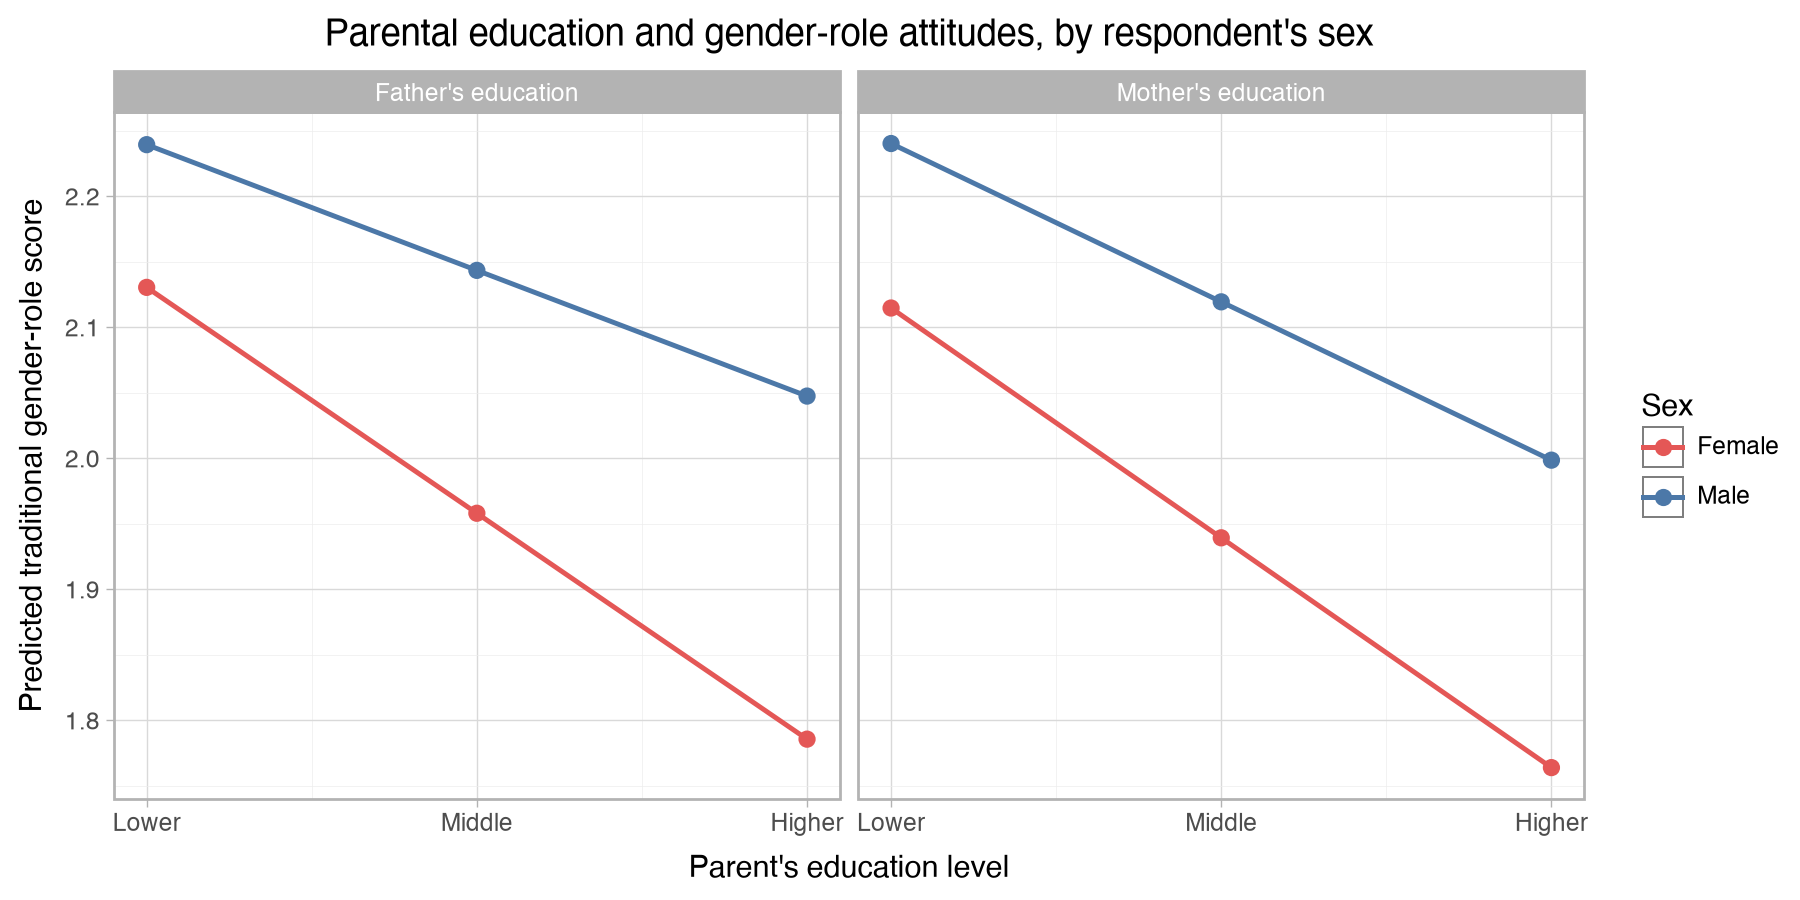

In [9]:
pred_rows = []  # list to collect predictions
for parent, model_name in [("Q277R", "Mother (a)"), ("Q278R", "Father (a)")]:  # one model per parent
    grid = pd.DataFrame([(edu, f) for edu in [1, 2, 3] for f in [0, 1]], columns=["education", "female"])  # all combinations
    grid[f"{parent}_c"] = grid["education"] - df[parent].mean()  # centre the education level, as in the model
    grid["predicted"] = sex_models[model_name].predict(grid)  # predicted gender-role score
    grid["Parent"] = parents[parent]  # label for the panel
    pred_rows.append(grid)  # store the predictions

pred = pd.concat(pred_rows)  # combine the predictions for both parents
pred["Sex"] = pred["female"].map({0: "Male", 1: "Female"})  # readable labels

p = (
    ggplot(pred, aes("education", "predicted", color="Sex"))  # x = education level, y = prediction, colour = sex
    + geom_line(size=1)  # one line per sex
    + geom_point(size=2.5)  # points at each education level
    + facet_wrap("~Parent")  # one panel per parent
    + scale_x_continuous(breaks=[1, 2, 3], labels=["Lower", "Middle", "Higher"])  # education labels
    + scale_color_manual(values={"Male": "#4C78A8", "Female": "#E45756"})  # colours for men and women
    + theme_light()  # clean background
    + labs(x="Parent's education level", y="Predicted traditional gender-role score",  # axis labels
           title="Parental education and gender-role attitudes, by respondent's sex")  # title
    + theme(figure_size=(9, 4.5))  # figure size
)
p.save(OUTPUT_FIGURES / "sex_differences_predicted.png", dpi=300, verbose=False)  # save the figure
p  # display the figure

### Interpretation

In both panels, the women's line (red) lies **below** the men's line (blue), so women are less traditional at every level of parental education. The lines are not parallel: the women's line slopes down more steeply, so the **predicted sex gap is larger among respondents with more highly educated parents**.

- **Mother's education:** among respondents whose mothers had lower education, the predicted gap between men and women is about **0.13** points. Among respondents whose mothers had higher education, it is about **0.24** points.
- **Father's education:** the pattern is a little more pronounced. The gap is about **0.11** points at lower education and about **0.26** points at higher education, which matches the larger (and significant) father × female interaction.

In other words, men and women whose parents had less education hold fairly similar gender-role attitudes, while **women with more highly educated parents had lower predicted traditional-attitude scores than men with similarly educated parents**. Because the data is cross-sectional, this describes a difference between groups of respondents. It does not show that daughters *become* less traditional because of their parents' education.

## 7. Is the `mother_more_educated` Association Different for Sons and Daughters?

Finally, we check whether having a mother who is more educated than the father is linked to gender-role attitudes differently for men and women. A household where the mother is the more educated parent might be a particularly strong role model for daughters. As in Model 2 of `06_multivariate_models.ipynb`, we control for both parents' education levels.

In [10]:
mme_model = smf.ols(f"{outcome} ~ mother_more_educated * female + Q277R_c + Q278R_c", data=df).fit()  # interaction model
print(mme_model.summary().tables[1])  # coefficient table
print(f"N = {int(mme_model.nobs)}")  # sample size

                                  coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
Intercept                       2.1994      0.020    111.880      0.000       2.161       2.238
mother_more_educated           -0.1865      0.090     -2.071      0.039      -0.363      -0.010
female                         -0.1500      0.027     -5.644      0.000      -0.202      -0.098
mother_more_educated:female    -0.0390      0.110     -0.356      0.722      -0.254       0.176
Q277R_c                        -0.0317      0.034     -0.927      0.354      -0.099       0.035
Q278R_c                        -0.1215      0.029     -4.252      0.000      -0.178      -0.065
N = 1773


### Interpretation

For men, `mother_more_educated` has a negative coefficient (b = **−0.1865**, p = .039). Because this indicator is derived from the two parental education values that are also in the model, this coefficient cannot be read as the effect of the mother being more educated *while holding both parents' education constant* (see `06_multivariate_models.ipynb`, Model 2, and `08_mother_more_educated.ipynb`, Section 5). The interaction with `female` is small and clearly **not significant** (b = −0.0390, p = .722), so the association is about the same for sons and daughters. We found no statistically significant evidence that a household where the mother is the more educated parent is a stronger role model specifically for daughters. The confidence interval for the interaction is wide (−0.254 to 0.176), however, because only 108 respondents have a more educated mother, so a modest difference cannot be ruled out.

## 8. Sensitivity Check: Parental Education as Categories

As in notebooks 05 and 06, the models above treat parental education as a numeric 1–2–3 score. To check whether the sex differences depend on this assumption, we refit models (a) and (b) with parental education as a **category** and test the two parent × female interaction terms together with an F-test. We also fit the controlled model (b) separately for men and women, to see the shape of each group's association.

In [11]:
from statsmodels.stats.anova import anova_lm  # F-test for nested models (Week 5)

cat_rows = []  # list to collect the joint tests
for parent, pname in parents.items():  # loop over mother and father
    for spec, extra in [("(a) no controls", ""), ("(b) age + own education", " + Q262 + Q275R")]:  # two specifications
        data = df.dropna(subset=[parent, outcome, "female"] + (["Q262", "Q275R"] if extra else []))  # complete cases
        main = smf.ols(f"{outcome} ~ C({parent}) + female{extra}", data=data).fit()  # no interaction
        inter = smf.ols(f"{outcome} ~ C({parent}) * female{extra}", data=data).fit()  # with the interaction
        f_test = anova_lm(main, inter)  # joint F-test of the two interaction terms
        cat_rows.append({"Parent": pname, "Model": spec, "N": int(inter.nobs),
                         "b Middle x Female": inter.params[f"C({parent})[T.2.0]:female"],
                         "b Higher x Female": inter.params[f"C({parent})[T.3.0]:female"],
                         "F (2 df)": f_test["F"].iloc[1], "p-value": f_test["Pr(>F)"].iloc[1]})

sex_categorical = pd.DataFrame(cat_rows)  # combine into a table
sex_categorical.to_csv(OUTPUT_TABLES / "sex_differences_categorical.csv", index=False)  # save the table
sex_categorical.round(4)  # display the table

,Parent,Model,N,b Middle x Female,b Higher x Female,F (2 df),p-value
0,Mother's education,(a) no controls,1851,-0.1096,-0.0537,1.5908,0.2040
1,Mother's education,(b) age + own education,1849,-0.0879,-0.0392,1.1028,0.3322
2,Father's education,(a) no controls,1791,-0.1003,-0.1430,2.5386,0.0793
3,Father's education,(b) age + own education,1790,-0.0859,-0.1170,1.9400,0.1440


In [12]:
by_sex_rows = []  # list to collect the results
for parent, pname in parents.items():  # loop over mother and father
    for sex in ["Male", "Female"]:  # separate models for men and women
        data = df[df["sex"] == sex].dropna(subset=[parent, outcome, "Q262", "Q275R"])  # complete cases for this group
        model = smf.ols(f"{outcome} ~ C({parent}) + Q262 + Q275R", data=data).fit()  # categorical model with controls
        for level, term in [("Middle vs Lower", f"C({parent})[T.2.0]"), ("Higher vs Lower", f"C({parent})[T.3.0]")]:
            by_sex_rows.append({"Parent": pname, "Sex": sex, "Contrast": level, "N": int(model.nobs),
                                "b": model.params[term], "p-value": model.pvalues[term]})

pd.DataFrame(by_sex_rows).round(4)  # display the table

,Parent,Sex,Contrast,N,b,p-value
0,Mother's education,Male,Middle vs Lower,847,0.0916,0.0556
1,Mother's education,Male,Higher vs Lower,847,-0.0967,0.1698
2,Mother's education,Female,Middle vs Lower,1002,0.0256,0.5742
3,Mother's education,Female,Higher vs Lower,1002,-0.1136,0.0535
4,Father's education,Male,Middle vs Lower,825,0.0842,0.0716
5,Father's education,Male,Higher vs Lower,825,-0.0064,0.9117
6,Father's education,Female,Middle vs Lower,965,0.0088,0.8317
7,Father's education,Female,Higher vs Lower,965,-0.1113,0.0434


### Interpretation

With categorical parental education, **none of the sex interactions is significant**: mother p = .204 (no controls) and p = .332 (with controls); father p = .079 and p = .144. This agrees with the main analysis. The only significant result there (father × female without controls, p = .030) depended partly on the numeric coding, and we have no robust evidence that the parental education slopes differ by sex.

The separate controlled models for men and women show that, compared with the Lower group, the **Higher** parental education group has somewhat lower scores among **women** (mother −0.114, p = .053; father −0.111, p = .043), but not among men (mother −0.097, p = .17; father −0.006, p = .91). Among **men**, the **Middle** group scores slightly *higher* than the Lower group (mother +0.092, p = .056; father +0.084, p = .072), which echoes the Middle-group pattern found in notebooks 06 and 10. These are many small tests on subgroups, so they are descriptive only.

## Summary

- **Women are less traditional than men** (M = 2.05 vs. 2.20), and men and women report similar levels of parental education.
- **The Spearman correlations between parental education and attitudes are larger for women** (ρ ≈ −.21) **than for men** (ρ ≈ −.12), for both mothers and fathers. We did not formally test whether these correlations differ.
- The **OLS interaction models** (which test whether the regression *slopes* differ by sex, not whether the Spearman correlations differ) only show a significant difference for **father's education without controls** (b3 = −0.077, p = .030). It is not significant once age and own education are adjusted for (p = .068), it is not significant with categorical parental education (p = .079), and none of the tests survives a correction for multiple testing.
- We found **no statistically significant evidence supporting the same-sex role model idea**: mother's education is not more strongly associated with women's attitudes, and father's education is not more strongly associated with men's. The `mother_more_educated` coefficient also does not differ significantly by sex (p = .722).
- After adjusting for age and own education, the parental education coefficients are **attenuated to approximately zero for men**. For **women** they are small (about −0.05) and **not statistically significant** (p ≈ .07).

**Interpretation:** the results are consistent with a tendency for women with more highly educated parents to hold less traditional attitudes than men with similarly educated parents. However, the evidence is weak (no test is robust to adjustment, categorical coding or multiple-testing correction), and the cross-sectional data cannot show *why* this happens. Explanations such as egalitarian attitudes being more directly in women's own interest are possible, but we cannot test them here.

**Limitations:** cross-sectional data; complete-case and **unweighted** analyses; self-reported parental education grouped into three levels and treated as numeric in the main models; several tests run on the same data; and sex is only measured as male/female by interviewer observation (Q260).